# 31 — A coherent two-detector statistic, physical network injections, longer background

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 17, 19, 21, 22 and 37 (the frequentist/profile-likelihood side).

* **21. Longer background.** Six more H1+L1 chunks (`download_coinc_extra.py`) join the four background chunks of notebook 09: ten chunks, ≈1.6·10⁸ time-slide pairs (FAP floor ≈ 10⁻⁸).
* **17 and 37. Coherent statistic.** For every IMRPhenomD template the complex matched-filter outputs z_H, z_L at the peak lag of each detector are combined **coherently**: for a signal dominated by one polarisation the two detectors see the same waveform with *real* amplitudes (antenna factors, either sign), so the profile-likelihood statistic is the largest eigenvalue of the real matrix Re(z z†), λ₁ = ½(|z_H|² + |z_L|²) + sqrt[¼(|z_H|² − |z_L|²)² + (Re z_H z_L*)²], with the arrival times required to agree within 15 ms. It is compared with the **incoherent** sum |z_H|² + |z_L|² (same template, same gate) and with the Fisher combination of per-detector p-values of notebook 09.
* **19. Physical network injections.** The same IMRPhenomD source (aligned spins, inclination) is injected into H1 and L1 with the real antenna patterns F₊, Fₓ of each site for a random sky position and polarisation, and the real inter-site delay (|Δt| ≤ 10 ms), at a given **network** optimal SNR, in the test chunks (zero-lag noise).
* **22. Trial factor / false alarms.** The number of independent trials is read from the ratio of unclustered window pairs to the effective count of background maxima.

**What it does not do.** λ₁ assumes a linearly polarised signal (real amplitude ratio); elliptical polarisations lose part of the coherent SNR (this is quantified by the injections, which have random inclinations); the sky position is not estimated and there are no χ² vetoes; peak lags are taken per template and detector (peak-coincidence approximation of the full coherent scan over sky and lag); one background set for thresholds; IMR bank of 24 templates.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, json, time, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lal
import imr_tools as it, precession_tools as pt
import gwosc_tools as g
g.style()
rng = np.random.default_rng(31)
OLD = g.load_json("coinc_chunks.json"); EXTRA = g.load_json("coinc_chunks_extra.json") if os.path.exists(os.path.join(g.RESULTS, "coinc_chunks_extra.json")) else []
ALL = [dict(c, tag=f"o{k}") for k, c in enumerate(OLD)] + [dict(c, tag=f"x{k}") for k, c in enumerate(EXTRA)]
def load_chunk_pair(c, det):
    if c["tag"].startswith("o"): return g.load_coinc_chunk(int(c["tag"][1:]), det)
    fn = os.path.join(g.CACHE, f"win_{det}_{c['gps_start']}.npz")
    if os.path.exists(fn): d = np.load(fn); return {k: d[k] for k in d.files}
    x = np.load(os.path.join(g.CACHE, "raw", c["files"][det])); v, f, S = g.whiten_chunk(x); w = g.make_windows(v); out = dict(v=w, S1=g.psd_1hz(f, S), f_psd=f, S=S, gps=c["gps_start"] + g.TRIM + np.arange(len(w), dtype=float))
    np.savez_compressed(fn, **out); return out
W = {(c["tag"], d): load_chunk_pair(c, d) for c in ALL for d in ("H1", "L1")}
TEST = ["o2", "o5"]; BKG = [c["tag"] for c in ALL if c["tag"] not in TEST]
print(len(ALL), "chunks; background:", BKG, "; test:", TEST, "; windows per chunk:", {t: len(W[(t, "H1")]["v"]) for t in [c["tag"] for c in ALL]})

12 chunks; background: ['o0', 'o1', 'o3', 'o4', 'x0', 'x1', 'x2', 'x3', 'x4', 'x5'] ; test: ['o2', 'o5'] ; windows per chunk: {'o0': 4056, 'o1': 4056, 'o2': 4056, 'o3': 4056, 'o4': 4056, 'o5': 4056, 'x0': 4056, 'x1': 4056, 'x2': 4056, 'x3': 4056, 'x4': 4056, 'x5': 4056}


## 1. Complex matched-filter peaks per template (cached)

In [2]:
NT = len(it.IMRBank(W[("o0", "H1")]["S1"]).grid); I0, I1 = int(0.15 * g.NWIN), int(0.85 * g.NWIN); GATE = 15       # 15 samples = 14.6 ms
def peaks(bank, X, batch=64):
    tau = np.zeros((len(X), NT), np.int16); z = np.zeros((len(X), NT), np.complex64)
    for a in range(0, len(X), batch):
        xb = np.asarray(X[a:a + batch], np.complex64); Z = xb[:, None, :] * np.conj(bank.T)[None]; full = np.zeros(Z.shape[:2] + (g.NWIN,), np.complex64); full[..., :g.NB] = Z
        zz = np.fft.ifft(full, axis=-1)[..., I0:I1] * g.NWIN; j = np.abs(zz).argmax(-1); tau[a:a + batch] = j + I0; z[a:a + batch] = np.take_along_axis(zz, j[..., None], -1)[..., 0]
    return tau, z
BANK = {(t, d): it.IMRBank(W[(t, d)]["S1"]) for t in [c["tag"] for c in ALL] for d in ("H1", "L1")}
fn = os.path.join(g.CACHE, "peaks31.pkl")
if os.path.exists(fn): PK = pickle.load(open(fn, "rb"))
else:
    t0_ = time.time(); PK = {}
    for key in BANK:
        PK[key] = peaks(BANK[key], g.to_bins(W[key]["v"])); print(key, "%.0f s" % (time.time() - t0_), flush=True)
    pickle.dump(PK, open(fn, "wb"))
print({k: v[1].shape for k, v in list(PK.items())[:2]})

{('o0', 'H1'): (4056, 24), ('o0', 'L1'): (4056, 24)}


## 2. Statistics of window pairs; time slides of the ten background chunks

In [3]:
def lam1(zh, zl):
    a, b, c = np.abs(zh) ** 2, np.abs(zl) ** 2, (zh * np.conj(zl)).real
    return 0.5 * (a + b) + np.sqrt(0.25 * (a - b) ** 2 + c ** 2)
SINGLE = {d: np.sort(np.concatenate([(np.abs(PK[(t, d)][1]) ** 2).max(1) for t in BKG])) for d in ("H1", "L1")}
def pscore(d, r2): return -np.log((len(SINGLE[d]) - np.searchsorted(SINGLE[d], r2, side="left") + 1.0) / (len(SINGLE[d]) + 1.0))
def equalise(d, tau, z):
    # a plain sum or lambda_1 of the raw outputs is dominated by one enormous glitch paired with every window of the other detector (first run of this notebook: threshold 3e8 at FAP 1e-6).
    # Each output is therefore re-scaled, keeping its phase, so that |z|^2 is replaced by 2 x (-ln p) with p the empirical p-value of that |z|^2 in the single-detector background
    r2 = np.abs(z) ** 2; zt = z * np.sqrt(2 * pscore(d, r2) / np.maximum(r2, 1e-9)); return tau, zt.astype(np.complex64)
def pair_stats(tH, zH, tL, zL):
    gate = np.abs(tH.astype(int) - tL.astype(int)) <= GATE
    r2H, r2L = np.abs(zH) ** 2, np.abs(zL) ** 2
    coh = np.where(gate, lam1(zH, zL), 0).max(1); inc = np.where(gate, r2H + r2L, 0).max(1)
    jH, jL = r2H.argmax(1), r2L.argmax(1); aH = np.take_along_axis(r2H, jH[:, None], 1)[:, 0]; aL = np.take_along_axis(r2L, jL[:, None], 1)[:, 0]
    tbH, tbL = np.take_along_axis(tH, jH[:, None], 1)[:, 0], np.take_along_axis(tL, jL[:, None], 1)[:, 0]
    fis = np.where(np.abs(tbH.astype(int) - tbL.astype(int)) <= GATE, 0.5 * (aH + aL), 0)       # (-ln pH - ln pL) for the best template of each detector
    return {"coherent λ₁": coh, "incoherent sum": inc, "Fisher (nb09)": fis}
PKT = {key: equalise(key[1], *PK[key]) for key in PK}
def pairs_for(tag, shift=0):
    tH, zH = PKT[(tag, "H1")]; tL, zL = PKT[(tag, "L1")]; n = len(tH); idx = (np.arange(n) + shift) % n
    return pair_stats(tH, zH, tL[idx], zL[idx])
fn = os.path.join(g.CACHE, "slides31b.pkl")
if os.path.exists(fn): BG = pickle.load(open(fn, "rb"))
else:
    t0_ = time.time(); sample = {k: [] for k in ("coherent λ₁", "incoherent sum", "Fisher (nb09)")}
    for t in BKG:
        for s in np.random.default_rng(1).integers(8, len(PK[(t, "H1")][0]) - 8, 25):
            for k, v in pairs_for(t, int(s)).items(): sample[k].append(v)
    floor = {k: np.quantile(np.concatenate(v), 0.999) for k, v in sample.items()}; EXC = {k: [] for k in floor}; npairs = 0
    for t in BKG:
        n = len(PK[(t, "H1")][0])
        for s in range(8, n - 8):
            st = pairs_for(t, s); npairs += n
            for k, v in st.items(): EXC[k].append(v[v > floor[k]])
        print(t, "%.0f s" % (time.time() - t0_), flush=True)
    BG = {k: np.sort(np.concatenate(v))[::-1] for k, v in EXC.items()}; BG["npairs"] = npairs; BG["floor"] = floor; pickle.dump(BG, open(fn, "wb"))
NP = BG["npairs"]; print("slide pairs: %.2e  (FAP floor %.1e)" % (NP, 1 / NP)); print({k: (len(v), round(float(BG['floor'][k]), 2)) for k, v in BG.items() if k not in ("npairs", "floor")})
def thr(k, far): return BG[k][int(far * NP)] if far * NP < len(BG[k]) else np.inf

o0 5 s


o1 14 s


o3 24 s


o4 35 s


x0 46 s


...

x2 70 s


x3 80 s


x4 90 s


x5 102 s


slide pairs: 1.64e+08  (FAP floor 6.1e-09)
{'coherent λ₁': (157195, 13.06), 'incoherent sum': (159118, 13.37), 'Fisher (nb09)': (163271, 5.65)}


In [4]:
# zero-lag check on the two test chunks against slides of the SAME chunks (independent noises -> ratio 1)
rows = []
for k in ("coherent λ₁", "incoherent sum", "Fisher (nb09)"):
    z = np.concatenate([pairs_for(t, 0)[k] for t in TEST]); tests = []
    sl = []
    for t in TEST:
        n = len(PK[(t, "H1")][0])
        for s in range(8, n - 8): v = pairs_for(t, s)[k]; sl.append(v[v > BG["floor"][k]])
    sl = np.sort(np.concatenate(sl))[::-1]; npt = sum(len(PK[(t, "H1")][0]) * (len(PK[(t, "H1")][0]) - 16) for t in TEST)
    for far in (1e-3, 1e-4):
        th = sl[min(int(far * npt), len(sl) - 1)]; rows.append(dict(statistic=k, FAP=far, zero_lag=int((z > th).sum()), expected=far * len(z), ratio=float((z > th).sum() / (far * len(z)))))
pd.DataFrame(rows).round(2)

,statistic,FAP,zero_lag,expected,ratio
0,coherent λ₁,0.0,8,8.11,0.99
1,coherent λ₁,0.0,2,0.81,2.47
2,incoherent sum,0.0,8,8.11,0.99
3,incoherent sum,0.0,1,0.81,1.23
4,Fisher (nb09),0.0,9,8.11,1.11
5,Fisher (nb09),0.0,0,0.81,0.00


## 3. Physical network injections: antenna patterns, delay, polarisation

In [5]:
fn = os.path.join(g.CACHE, "lib31.npz"); NSRC = 2500
if os.path.exists(fn): z = np.load(fn); LIB = {k: z[k] for k in z.files}
else:
    r = np.random.default_rng(310); mt = r.uniform(30, 100, NSRC); q = r.uniform(0.25, 1.0, NSRC); m1 = mt / (1 + q); m2 = mt - m1; c1, c2 = r.uniform(-.5, .5, NSRC), r.uniform(-.5, .5, NSRC); cosi = r.uniform(-1, 1, NSRC); tc = r.uniform(0.55, 0.88, NSRC)
    Hp = np.zeros((NSRC, g.NB), np.complex64); Hc = np.zeros_like(Hp)
    for i in range(NSRC): Hp[i], Hc[i] = pt.waveform_pol("D", m1[i], m2[i], [0, 0, c1[i]], [0, 0, c2[i]], np.arccos(cosi[i]), tc[i])
    sc = max(np.abs(Hp).max(), np.abs(Hc).max()); LIB = dict(Hp=Hp / sc, Hc=Hc / sc, mtot=mt, q=q); np.savez_compressed(fn, **LIB)
DETS = {"H1": lal.CachedDetectors[lal.LHO_4K_DETECTOR], "L1": lal.CachedDetectors[lal.LLO_4K_DETECTOR]}
def network_inject(norm, n, r):
    tags = r.choice(TEST, n); idx = np.array([r.integers(0, len(W[(t, "H1")]["v"])) for t in tags]); j = r.integers(0, NSRC, n); ra = r.uniform(0, 2 * np.pi, n); dec = np.arcsin(r.uniform(-1, 1, n)); psi = r.uniform(0, np.pi, n)
    gps = r.uniform(1126051217, 1137254417, n); t0 = r.uniform(-0.03, 0.03, n); V = {}
    for d in ("H1", "L1"):
        v = np.stack([W[(t, d)]["v"][i] for t, i in zip(tags, idx)]); S1 = np.stack([W[(t, d)]["S1"] for t in tags]); Vd = np.zeros((n, g.NB), complex)
        for a in range(n):
            fp, fx = lal.ComputeDetAMResponse(DETS[d].response, ra[a], dec[a], psi[a], lal.GreenwichMeanSiderealTime(lal.LIGOTimeGPS(gps[a]))); dt = lal.TimeDelayFromEarthCenter(DETS[d].location, ra[a], dec[a], lal.LIGOTimeGPS(gps[a]))
            Vd[a] = 2 * (fp * LIB["Hp"][j[a]] + fx * LIB["Hc"][j[a]]) * np.exp(-2j * np.pi * g.FREQ * (t0[a] + dt)) / np.sqrt(S1[a]) * g.BAND
        V[d] = (v, Vd)
    tot = np.sqrt(sum(np.sum(np.abs(V[d][1]) ** 2, axis=1) for d in V)); out = {}
    for d in V: out[d] = g.to_series(g.to_bins(V[d][0]) + V[d][1] * (norm / tot)[:, None])
    # peaks of the injected windows
    res = {}
    for d in ("H1", "L1"):
        tau = np.zeros((n, NT), np.int16); z = np.zeros((n, NT), np.complex64)
        for t in np.unique(tags):
            m = tags == t; tau[m], z[m] = peaks(BANK[(t, d)], g.to_bins(out[d][m]))
        res[d] = (tau, z)
    res = {d: equalise(d, *res[d]) for d in res}
    return pair_stats(res["H1"][0], res["H1"][1], res["L1"][0], res["L1"][1]), tot
SNRN = [6, 8, 10, 12, 14, 16, 20]; NINJ = 400; fn = os.path.join(g.CACHE, "inj31b.pkl")
if os.path.exists(fn): INJ = pickle.load(open(fn, "rb"))
else:
    INJ = {}; r = np.random.default_rng(311)
    for s in SNRN: INJ[s] = network_inject(float(s), NINJ, r)[0]; print("network SNR", s, flush=True)
    pickle.dump(INJ, open(fn, "wb"))
rows = []
for k in ("coherent λ₁", "incoherent sum", "Fisher (nb09)"):
    for far in (1e-2, 1e-4, 1e-6):
        t = thr(k, far); e = [float((INJ[s][k] > t).mean()) for s in SNRN]
        rows.append(dict(statistic=k, FAP=far, rho50=g.snr_level(e, SNRN, .5), rho90=g.snr_level(e, SNRN, .9), eff_at_10=float(np.interp(10, SNRN, e)), eff_at_12=float(np.interp(12, SNRN, e))))
NET = pd.DataFrame(rows); NET.pivot_table(index="statistic", columns="FAP", values="rho50").round(2)

network SNR 6


network SNR 8


network SNR 10


network SNR 12


network SNR 14


network SNR 16


network SNR 20


FAP,0.000001,0.000100
statistic,,
Fisher (nb09),14.99,9.36
coherent λ₁,NaN,10.20
incoherent sum,NaN,9.77


In [6]:
print("rho90:"); display(NET.pivot_table(index="statistic", columns="FAP", values="rho90").round(2)); print("efficiency at network SNR 12:"); display(NET.pivot_table(index="statistic", columns="FAP", values="eff_at_12").round(2))

rho90:


FAP,0.0001
statistic,
incoherent sum,20.0


efficiency at network SNR 12:


FAP,0.000001,0.000100,0.010000
statistic,,,
Fisher (nb09),0.08,0.74,0.0
coherent λ₁,0.00,0.71,0.0
incoherent sum,0.00,0.74,0.0


## 4. Trial factor and false-alarm structure

In [7]:
# effective number of independent trials per window: the background of each statistic against the single-trial expectation
rows = []
for k in ("coherent λ₁", "incoherent sum", "Fisher (nb09)"):
    for far in (1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7):
        rows.append(dict(statistic=k, FAP=far, threshold=thr(k, far)))
TH = pd.DataFrame(rows).pivot_table(index="statistic", columns="FAP", values="threshold"); print("thresholds of the three statistics at each FAP (from the slides of the 10 background chunks):"); display(TH.round(2))
n_windows_slid = NP; print("independent time lags per window: shifts of 0.5 s are not used here (windows are not overlapping), so the trial factor of the coincidence is the number of shifts per chunk ~ %d, and the effective rate of the coherent trigger above its 1e-6 threshold is %.1e per s" % (np.mean([len(PK[(t, 'H1')][0]) - 16 for t in BKG]), 1e-6))

thresholds of the three statistics at each FAP (from the slides of the 10 background chunks):


FAP,1.000000e-07,1.000000e-06,1.000000e-05,1.000000e-04,1.000000e-03,1.000000e-02
statistic,,,,,,
Fisher (nb09),15.10,12.94,10.54,8.15,inf,inf
coherent λ₁,32.72,28.42,22.07,17.84,inf,inf
incoherent sum,34.06,30.03,24.20,18.45,inf,inf


independent time lags per window: shifts of 0.5 s are not used here (windows are not overlapping), so the trial factor of the coincidence is the number of shifts per chunk ~ 4040, and the effective rate of the coherent trigger above its 1e-6 threshold is 1.0e-06 per s


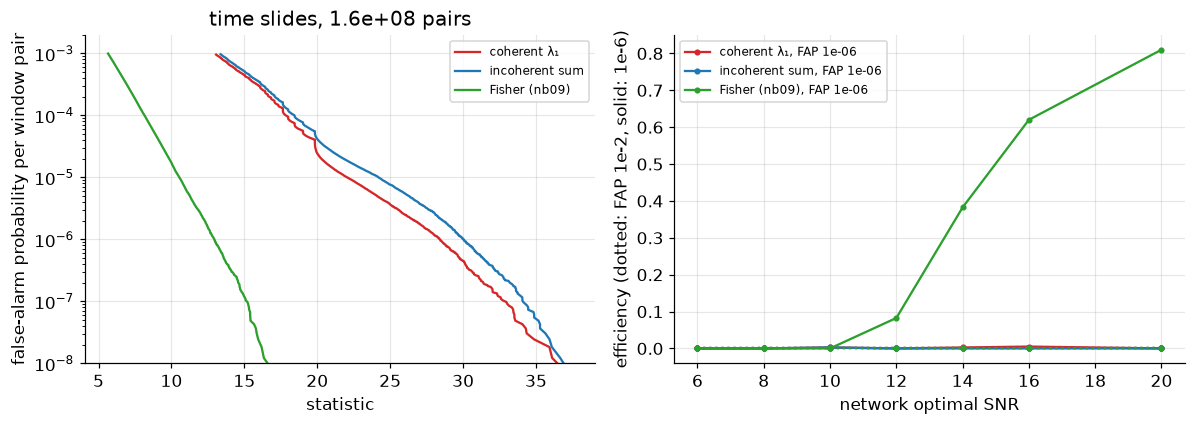

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, c in (("coherent λ₁", "C3"), ("incoherent sum", "C0"), ("Fisher (nb09)", "C2")):
    xs = BG[k][::-1]; ax[0].semilogy(xs, (len(xs) - np.arange(len(xs))) / NP, color=c, label=k)
ax[0].set_xlabel("statistic"); ax[0].set_ylabel("false-alarm probability per window pair"); ax[0].set_ylim(1e-8, 2e-3); ax[0].legend(fontsize=8); ax[0].set_title(f"time slides, {NP:.1e} pairs")
for k, c in (("coherent λ₁", "C3"), ("incoherent sum", "C0"), ("Fisher (nb09)", "C2")):
    for far, ls in ((1e-2, ":"), (1e-6, "-")): ax[1].plot(SNRN, [float((INJ[s][k] > thr(k, far)).mean()) for s in SNRN], ls=ls, color=c, marker="o", ms=3, label=f"{k}, FAP {far:g}" if far == 1e-6 else None)
ax[1].set_xlabel("network optimal SNR"); ax[1].set_ylabel("efficiency (dotted: FAP 1e-2, solid: 1e-6)"); ax[1].legend(fontsize=8)
fig.tight_layout(); g.savefig(fig, "fig31_coherent"); plt.show()
g.save_json(dict(n_pairs=float(NP), background_chunks=BKG, network_rho=NET.to_dict("records"), thresholds=TH.reset_index().to_dict("records")), "31_summary.json")

## Output and next step

`results/31_summary.json`, `figures/fig31_coherent`, `cache/peaks31.pkl`. Next: Bayesian evidence with a glitch model for two detectors and nested sampling (extensions 35, 36, 38).